In [1]:
from google.colab import drive
drive.mount('/content/drive')
import numpy as np
import pandas as pd


Mounted at /content/drive


In [2]:

train_X = pd.read_csv('/content/drive/MyDrive/2026Projects/nameThatLLM/dataset/train.csv')
test_X = pd.read_csv('/content/drive/MyDrive/2026Projects/nameThatLLM/dataset/test.csv')

In [3]:
train_X

,id,prompt_id,text,model
0,0018b3765972,p081,"When a language dies, a particular astronomy d...",qwen3.8-max
1,0041ac86ee93,p073,Data science communities matter because they a...,claude-sonnet-5
2,005a19083eae,p120,"In the final twilight of time, the last embers...",gemini-3.6-flash
3,009319596f10,p073,Data science communities matter because they t...,gpt-5.6-terra
4,00d3e8c92596,p097,"Deep inside each ear, three tiny loops of bone...",glm-5.3-flash
...,...,...,...,...
2694,ff4344ceda23,p075,"Across centuries of silence and shadow, an inv...",gemini-3.8-flash
2695,ff507658ba82,p092,Though both instruments breathe the exact same...,gemini-3.7-flash
2696,ff50c252810c,p113,A single photon leaves the star as neither wav...,claude-opus-4-8
2697,ffcf6321f7e9,p073,Data science communities matter because they t...,glm-5.3


### Exploratory Data Analysis (EDA)
We will analyze the target classes, prompt distribution, and text length statistics.

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Target Class Distribution
print("=== Model Class Distribution ===")
model_counts = train_X['model'].value_counts()
print(model_counts)

# 2. Unique Prompts count
print("\n=== Unique Prompts ===")
print(f"Number of unique prompts: {train_X['prompt_id'].nunique()}")

# 3. Calculate text lengths
train_X['char_len'] = train_X['text'].astype(str).apply(len)
train_X['word_len'] = train_X['text'].astype(str).apply(lambda x: len(x.split()))

print("\n=== Text Length Statistics (Characters) ===")
print(train_X['char_len'].describe())

print("\n=== Text Length Statistics (Words) ===")
print(train_X['word_len'].describe())

=== Model Class Distribution ===
model
qwen3.8-max               150
claude-sonnet-5           150
gemini-3.6-flash          150
gpt-5.6-terra             150
glm-5.3-flash             150
gemini-3.1-pro-preview    150
gemini-3.8-flash          150
claude-opus-4-6           150
gpt-5.6-luna              150
claude-opus-4-8           150
gemini-3.7-flash          150
claude-opus-5             150
kimi-k3                   150
gpt-5.5                   150
glm-5.3                   150
gpt-6-astra               150
gpt-5.6-sol               150
claude-fable-5            149
Name: count, dtype: int64

=== Unique Prompts ===
Number of unique prompts: 150

=== Text Length Statistics (Characters) ===
count    2699.000000
mean      755.289366
std       377.371075
min       230.000000
25%       429.000000
50%       670.000000
75%      1027.000000
max      1900.000000
Name: char_len, dtype: float64

=== Text Length Statistics (Words) ===
count    2699.000000
mean      114.659504
std        58.2

/tmp/ipykernel_1349/1133294725.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=train_X, y='model', order=model_counts.index, ax=axes[0], palette='viridis')


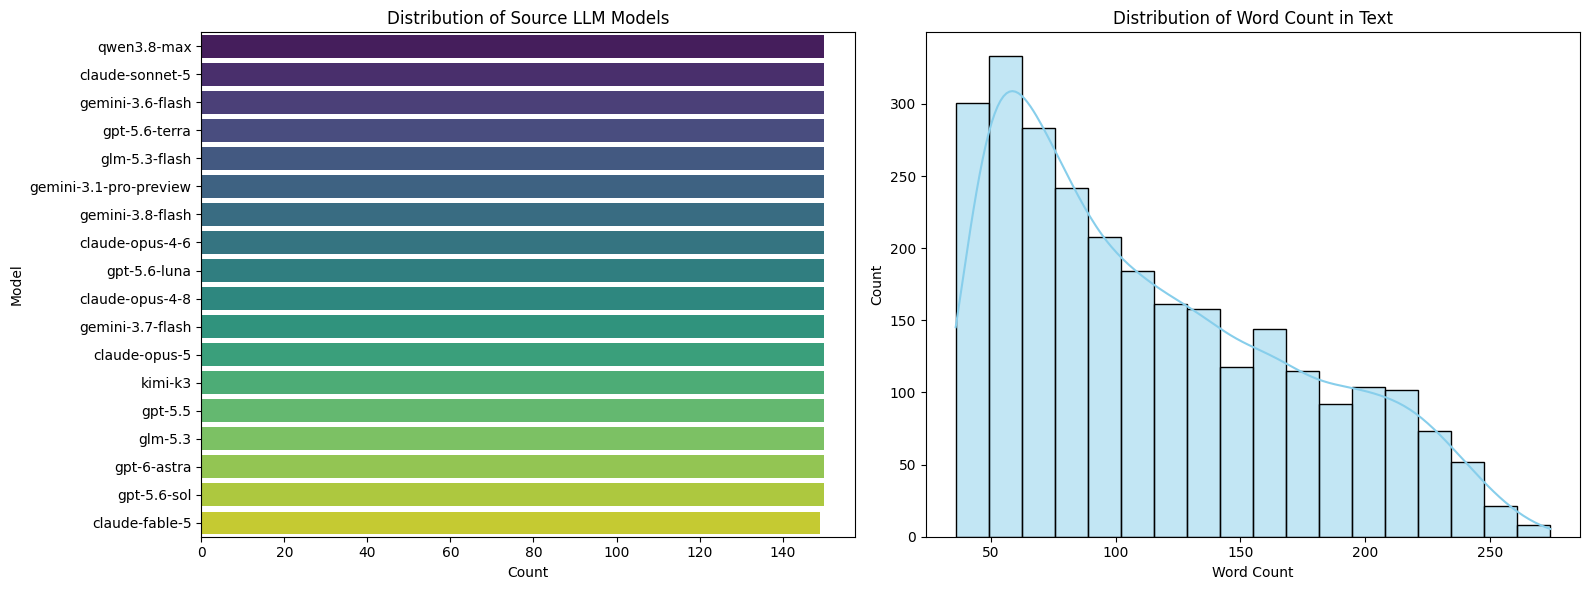

In [5]:
# Visualize the distributions
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.countplot(data=train_X, y='model', order=model_counts.index, ax=axes[0], palette='viridis')
axes[0].set_title('Distribution of Source LLM Models')
axes[0].set_xlabel('Count')
axes[0].set_ylabel('Model')

sns.histplot(data=train_X, x='word_len', kde=True, ax=axes[1], color='skyblue')
axes[1].set_title('Distribution of Word Count in Text')
axes[1].set_xlabel('Word Count')

plt.tight_layout()
plt.show()

### Baseline Model: TF-IDF + Logistic Regression
We will use a combined Word + Char TF-IDF representation and evaluate it using Stratified 5-Fold Cross Validation.

In [6]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import FeatureUnion
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder
import numpy as np

# 1. Encode Target Labels
le = LabelEncoder()
y = le.fit_transform(train_X['model'])
X_text = train_X['text']

# 2. Build Feature Extractor
# Word n-grams and character n-grams to capture stylistic patterns
word_vectorizer = TfidfVectorizer(
    sublinear_tf=True,
    strip_accents='unicode',
    analyzer='word',
    token_pattern=r'\w{1,}',
    ngram_range=(1, 2),
    max_features=15000
)

char_vectorizer = TfidfVectorizer(
    sublinear_tf=True,
    strip_accents='unicode',
    analyzer='char',
    ngram_range=(2, 5),
    max_features=30000
)

vectorizer = FeatureUnion([
    ('word', word_vectorizer),
    ('char', char_vectorizer)
])

print('Extracting features...')
X_features = vectorizer.fit_transform(X_text)
print(f'Feature matrix shape: {X_features.shape}')

Extracting features...
Feature matrix shape: (2699, 45000)


In [7]:
# 3. Evaluate using Stratified 5-Fold CV
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
clf = LogisticRegression(C=2.0, max_iter=1000, solver='saga', multi_class='multinomial', n_jobs=-1)

print('Running cross-validation...')
scores = cross_val_score(clf, X_features, y, cv=cv, scoring='accuracy', n_jobs=-1)

print(f'Mean CV Accuracy: {np.mean(scores):.4f} (+/- {np.std(scores):.4f})')

Running cross-validation...
Mean CV Accuracy: 0.1156 (+/- 0.0066)


### Baseline Model: TF-IDF + Logistic Regression
We will use a combined Word + Char TF-IDF representation and evaluate it using Stratified 5-Fold Cross Validation.

In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import FeatureUnion
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder
import numpy as np

# 1. Encode Target Labels
le = LabelEncoder()
y = le.fit_transform(train_X['model'])
X_text = train_X['text']

# 2. Build Feature Extractor
# Word n-grams and character n-grams to capture stylistic patterns
word_vectorizer = TfidfVectorizer(
    sublinear_tf=True,
    strip_accents='unicode',
    analyzer='word',
    token_pattern=r'\w{1,}',
    ngram_range=(1, 2),
    max_features=15000
)

char_vectorizer = TfidfVectorizer(
    sublinear_tf=True,
    strip_accents='unicode',
    analyzer='char',
    ngram_range=(2, 5),
    max_features=30000
)

vectorizer = FeatureUnion([
    ('word', word_vectorizer),
    ('char', char_vectorizer)
])

print("Extracting features...")
X_features = vectorizer.fit_transform(X_text)
print(f"Feature matrix shape: {X_features.shape}")

Extracting features...
Feature matrix shape: (2699, 45000)


In [9]:
# 3. Evaluate using Stratified 5-Fold CV
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
clf = LogisticRegression(C=2.0, max_iter=1000, solver='saga', multi_class='multinomial', n_jobs=-1)

print("Running cross-validation...")
scores = cross_val_score(clf, X_features, y, cv=cv, scoring='accuracy', n_jobs=-1)

print(f"Mean CV Accuracy: {np.mean(scores):.4f} (+/- {np.std(scores):.4f})")

Running cross-validation...
Mean CV Accuracy: 0.1156 (+/- 0.0058)


### Transformer Model: DeBERTa-v3 Fine-tuning
We will use `transformers` and `datasets` to fine-tune a pre-trained `DeBERTa-v3-small` model. First, we install the required packages.

In [10]:
!pip install -q transformers[torch] datasets accelerate evaluate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 4.3 MB/s eta 0:00:00


In [11]:
import torch
from datasets import Dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer
import numpy as np
import evaluate

# Check for GPU availability
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Using device: {device}')

# Use 'microsoft/deberta-v3-small' as it is highly efficient and powerful for text classification
MODEL_NAME = 'microsoft/deberta-v3-small'
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, use_fast=True)

# Prepare training and validation split (e.g., 85% train, 15% validation)
df_train = train_X.sample(frac=1, random_state=42).reset_index(drop=True)
df_train['label'] = le.transform(df_train['model'])

train_split = df_train.sample(frac=0.85, random_state=42)
val_split = df_train.drop(train_split.index)

train_dataset = Dataset.from_pandas(train_split[['text', 'label']])
val_dataset = Dataset.from_pandas(val_split[['text', 'label']])

def tokenize_function(examples):
    return tokenizer(examples['text'], truncation=True, max_length=512)

tokenized_train = train_dataset.map(tokenize_function, batched=True)
tokenized_val = val_dataset.map(tokenize_function, batched=True)

# Load accuracy metric
metric = evaluate.load('accuracy')
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return metric.compute(predictions=predictions, references=labels)

Using device: cuda


config.json:   0%|          | 0.00/578 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 2.46MB            

spm.model: downloading bytes:           |  0.00B            

Map:   0%|          | 0/2294 [00:00<?, ? examples/s]

Map:   0%|          | 0/405 [00:00<?, ? examples/s]

In [15]:
# Load the pre-trained Sequence Classification model
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(le.classes_)
)

training_args = TrainingArguments(
    output_dir='./results',
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=16,
    num_train_epochs=3,
    weight_decay=0.01,
    eval_strategy='epoch',
    save_strategy='epoch',
    load_best_model_at_end=True,
    metric_for_best_model='accuracy',
    fp16=False,  # Disabled to fix 'Attempting to unscale FP16 gradients' error
    report_to='none'
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_val,
    processing_class=tokenizer,
    compute_metrics=compute_metrics
)

# Run the fine-tuning process
trainer.train()

Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     | 
----------------------------------------+------------+-
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
classifier.weight                       | MISSING    | 
classifier.bias                         | MISSING    | 
pooler.dense.weight                     | MISSING    | 
pooler.de

Epoch,Training Loss,Validation Loss,Accuracy
1,No log,nan,0.054321
2,7.544410,nan,0.054321
3,7.544410,nan,0.054321


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=861, training_loss=4.381190283373257, metrics={'train_runtime': 117.4401, 'train_samples_per_second': 58.6, 'train_steps_per_second': 7.331, 'total_flos': 443150424628416.0, 'train_loss': 4.381190283373257, 'epoch': 3.0})

### Transformer Model: DeBERTa-v3 Fine-tuning
We will use `transformers` and `datasets` to fine-tune a pre-trained `DeBERTa-v3` model. First, let's install the required libraries.

In [16]:
!pip install -q transformers[torch] datasets accelerate evaluate

In [27]:
import torch
from datasets import Dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer
import numpy as np
import evaluate

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Using device: {device}")

# Switch to RoBERTa-base which is highly stable and does not suffer from DeBERTa-v3's NaN bug
MODEL_NAME = 'roberta-base'
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, use_fast=True)

df_train = train_X.sample(frac=1, random_state=42).reset_index(drop=True)
df_train['label'] = le.transform(df_train['model'])

train_split = df_train.sample(frac=0.85, random_state=42)
val_split = df_train.drop(train_split.index)

train_dataset = Dataset.from_pandas(train_split[['text', 'label']])
val_dataset = Dataset.from_pandas(val_split[['text', 'label']])

def tokenize_function(examples):
    return tokenizer(examples['text'], truncation=True, max_length=512)

tokenized_train = train_dataset.map(tokenize_function, batched=True)
tokenized_val = val_dataset.map(tokenize_function, batched=True)

metric = evaluate.load('accuracy')
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return metric.compute(predictions=predictions, references=labels)

Using device: cuda


config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Map:   0%|          | 0/2294 [00:00<?, ? examples/s]

Map:   0%|          | 0/405 [00:00<?, ? examples/s]

In [19]:
# Load the pre-trained Sequence Classification model
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(le.classes_)
)

training_args = TrainingArguments(
    output_dir='./results',
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=16,
    num_train_epochs=3,
    weight_decay=0.01,
    eval_strategy='epoch',
    save_strategy='epoch',
    load_best_model_at_end=True,
    metric_for_best_model='accuracy',
    fp16=False,
    report_to='none'
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_val,
    processing_class=tokenizer,
    compute_metrics=compute_metrics
)

# Run the fine-tuning process
trainer.train()

Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     | 
----------------------------------------+------------+-
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
classifier.weight                       | MISSING    | 
classifier.bias                         | MISSING    | 
pooler.dense.weight                     | MISSING    | 
pooler.de

Epoch,Training Loss,Validation Loss,Accuracy
1,No log,nan,0.054321
2,2.895804,nan,0.054321
3,2.895804,nan,0.054321


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=861, training_loss=1.681651400079849, metrics={'train_runtime': 128.6492, 'train_samples_per_second': 53.494, 'train_steps_per_second': 6.693, 'total_flos': 443150424628416.0, 'train_loss': 1.681651400079849, 'epoch': 3.0})

In [21]:
# Evaluate the model on the validation dataset
eval_results = trainer.evaluate()

print("=== Validation Evaluation Results ===")
for key, value in eval_results.items():
    print(f"{key}: {value}")

Training Loss,Validation Loss,Epoch,Accuracy
2.895804,nan,3,0.054321


=== Validation Evaluation Results ===
eval_loss: nan
eval_accuracy: 0.05432098765432099


In [28]:
import shutil
import gc
import torch

gc.collect()
torch.cuda.empty_cache()

shutil.rmtree('./results_stable', ignore_errors=True)
shutil.rmtree('./results', ignore_errors=True)

print("Memory cleared and previous checkpoints removed.")

stable_training_args = TrainingArguments(
    output_dir='./results_stable',
    learning_rate=2e-5,              # Standard learning rate is now safe with RoBERTa
    per_device_train_batch_size=8,
    per_device_eval_batch_size=16,
    num_train_epochs=2,
    weight_decay=0.01,
    warmup_steps=100,
    max_grad_norm=1.0,
    eval_strategy='epoch',
    save_strategy='epoch',
    load_best_model_at_end=True,
    metric_for_best_model='accuracy',
    fp16=False,
    report_to='none'
)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(le.classes_)
)

stable_trainer = Trainer(
    model=model,
    args=stable_training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_val,
    processing_class=tokenizer,
    compute_metrics=compute_metrics
)

print("Starting stable training run with RoBERTa...")
stable_trainer.train()

Memory cleared and previous checkpoints removed.


model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
classifier.out_proj.bias   | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Starting stable training run with RoBERTa...


Epoch,Training Loss,Validation Loss,Accuracy
1,No log,2.440967,0.125926
2,2.500952,1.991746,0.251852


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=574, training_loss=2.4480914604373094, metrics={'train_runtime': 269.3542, 'train_samples_per_second': 17.033, 'train_steps_per_second': 2.131, 'total_flos': 624759578394696.0, 'train_loss': 2.4480914604373094, 'epoch': 2.0})

In [29]:
# Re-evaluate the stable RoBERTa model
stable_eval_results = stable_trainer.evaluate()
print("=== Stabilized RoBERTa Model Evaluation Results ===")
for key, value in stable_eval_results.items():
    print(f"{key}: {value}")

Training Loss,Validation Loss,Epoch,Accuracy
2.500952,1.991746,2,0.251852


=== Stabilized RoBERTa Model Evaluation Results ===
eval_loss: 1.9917460680007935
eval_accuracy: 0.2518518518518518


### Generate Predictions for Kaggle Submission
We will tokenize the test dataset, get predictions from our trained `stable_trainer`, map the label IDs back to model names using our `LabelEncoder`, and export the results to `submission.parquet`.

In [30]:
from datasets import Dataset
import pandas as pd
import numpy as np

# 1. Convert test set to Hugging Face Dataset format
test_dataset = Dataset.from_pandas(test_X[['text']])

# 2. Tokenize using our RoBERTa tokenizer
def tokenize_test_function(examples):
    return tokenizer(examples['text'], truncation=True, max_length=512)

tokenized_test = test_dataset.map(tokenize_test_function, batched=True)

# 3. Predict logits using our trained stable_trainer
print("Generating test predictions...")
test_predictions = stable_trainer.predict(tokenized_test)

# 4. Convert logits to label IDs
predicted_label_ids = np.argmax(test_predictions.predictions, axis=-1)

# 5. Inverse-transform back to original model names
predicted_model_names = le.inverse_transform(predicted_label_ids)

# 6. Build the submission DataFrame
# Double check that 'id' is in test_X and matches Kaggle's required format
submission_df = pd.DataFrame({
    'id': test_X['id'],
    'model': predicted_model_names
})

# 7. Save to submission.parquet as required
submission_path = 'submission.parquet'
submission_df.to_parquet(submission_path, index=False)
print(f"Submission successfully saved to {submission_path}!")
display(submission_df.head())


Map:   0%|          | 0/3 [00:00<?, ? examples/s]

Generating test predictions...


Submission successfully saved to submission.parquet!


,id,model
0,00353fb1c541,glm-5.3-flash
1,005f5a9a6139,gpt-6-astra
2,0062a53d5487,gemini-3.7-flash


### Submit via Kaggle CLI

Once the `submission.parquet` file has been generated and you have your Kaggle API key configured, you can submit using this command:

```bash
kaggle competitions submit -c name-that-llm -f submission.parquet -m "Initial Stable RoBERTa Submission"
```